# 23 · A7: neighbourhood context and more training places for the land map

Fixed in `PLAN.md` (amendment A7) before this notebook ran. Matt: *"yes, run the land-map test"*, with his rule
against hacks (*"I don't want hacks, ideally we want a method that doesn't have rules for certain stuff"*): every
change applies to all classes the same way.

- **A5 (baseline):** the stored multinomial model on each pixel's 64 AlphaEarth numbers.
- **N:** + the mean of the valid pixels in 5 × 5 (150 m) and 15 × 15 (450 m) windows and the 15 × 15 standard
  deviation (256 features, standardised), multinomial, argmax.
- **M:** A5's model fitted on 16 more training tiles (8 random points in the training states, 8 centred on random
  solar farms there; ≥ 30 km from every other tile; seed 0).
- **N+M:** both.

Scored like A5 on the held-out states (Minnesota, Georgia) at 90 m. Pass marks: **L1** macro-F1 gain ≥ +0.02 with
95% interval lower bound > 0; **L2** median question F1 change ≥ −0.01 and at most 5% of questions worse by > 0.10.

In [1]:
import json
import time
from dataclasses import replace

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from askmap.config import PROJECT_ROOT, data_root, load_config, load_env
from askmap.data import read_uspvdb
from askmap.demo.core import class_shares
from askmap.demo.engine import Engine
from askmap.demo.serve import load_tiles, make_contexts
from askmap.earth_engine import init_earth_engine
from askmap.geo import make_tile
from askmap.landctx import (
    context_features,
    fit_scaled_multinomial,
    natural_sample_tiles,
    pick_new_tiles,
    scaled_onehot,
)
from askmap.landmaps import (
    argmax_onehot,
    block_counts,
    bootstrap_macro_diff,
    class_scores,
    fit_multinomial,
    macro_f1,
)
from askmap.layers import SOLAR_LATER, official_leaf_map
from askmap.manifest import Manifest
from askmap.plan import execute
from askmap.score import pooled_counts
from askmap.tiles import area_tiles, build_ee_tile, save_tile

load_env()
cfg = load_config(PROJECT_ROOT / "configs" / "feasibility.yaml")
CAP = load_config(PROJECT_ROOT / "configs" / "captions.yaml")
QUERIES = load_config(PROJECT_ROOT / "configs" / "queries.yaml")["queries"]
ROOT = data_root()
RES = PROJECT_ROOT / "outputs" / "results"
FIG = PROJECT_ROOT / "outputs" / "figures"
DEMO = ROOT / "demo"
TILE_DIR = ROOT / "tiles"
meta = json.loads((DEMO / "meta.json").read_text())
CL = cfg["classes"]
LEAVES = CL["leaves"]
OTHER = LEAVES.index("other")
HELD = cfg["heldout_pools"]  # question area -> held-out state
SEEN = list(HELD)
STRIDE = meta["stride"]
YEAR, U = cfg["land_year"], cfg["uspvdb"]
N_SAMPLE, SEED, BLOCK, NB, MIN_TRUE = 500_000, 0, 10, 1000, 50
MEAN_SIZES, STD_SIZE = (5, 15), 15
N_RANDOM, N_FARMS, MIN_KM = 8, 8, 30
TRAIN_STATES = ["ND", "NC", "SD", "NE", "KS", "VA", "SC"]
METHODS = ["A5", "N", "M", "NM"]
T_START = time.time()

## (M) 16 new training tiles: the fixed rule, then Earth Engine

In [2]:
pv = read_uspvdb(ROOT / "raw" / "uspvdbGeoJSON.zip", U["member"])
farms = pv[pv.p_year.notna() & (pv.p_year <= U["last_year"])]
states = gpd.read_file(f"zip://{ROOT / 'raw' / 'cb_2023_us_state_20m.zip'}")
existing = [
    (lon, lat)
    for a in cfg["areas"].values()
    for role in ("train_tiles", "test_tiles")
    for lon, lat in a.get(role, {}).values()
]
NEW = pick_new_tiles(states, TRAIN_STATES, farms, N_RANDOM, N_FARMS, existing, MIN_KM, SEED)
manifest = Manifest(TILE_DIR)
ee_ready, rows = False, []
for name, lon, lat in NEW:
    tile = make_tile(name, lon, lat, cfg["grid"]["tile_size_m"], cfg["grid"]["res_m"])
    path = TILE_DIR / f"more_{name}.npz"
    t0 = time.time()
    if not manifest.is_current(path):
        if not ee_ready:
            _ = init_earth_engine()  # the project ID is read from .env and not printed
            ee_ready = True
        arrays = build_ee_tile(tile, YEAR, pv, U["last_year"])
        save_tile(
            path,
            arrays,
            manifest,
            area="more",
            tile=name,
            year=YEAR,
            source="Earth Engine + USPVDB",
            x0=tile.x0,
            y1=tile.y1,
            size_px=tile.size_px,
            res_m=tile.res_m,
            rule="A7",
        )
    z = np.load(path)
    st = states[states.geometry.contains(gpd.points_from_xy([lon], [lat], crs=4326)[0])]
    rows.append(
        {
            "tile": name,
            "lon": round(lon, 3),
            "lat": round(lat, 3),
            "state": st.STUSPS.iloc[0] if len(st) else "?",
            "seconds": round(time.time() - t0, 1),
            "solar_px": int((z["solar"] == 1).sum()),
            # pixels without an embedding are recorded; they are never sampled (only finite pixels are)
            "missing_embedding_share": round(float(np.isnan(z["ae"]).any(axis=0).mean()), 4),
        }
    )
NEW_TILES = pd.DataFrame(rows)
NEW_TILES

,tile,lon,lat,state,seconds,solar_px,missing_embedding_share
0,R1,-83.159,35.183,NC,0.1,0,0.0
1,R2,-95.064,39.857,KS,0.0,0,0.0
2,R3,-100.205,44.619,SD,0.0,0,0.0
3,R4,-76.873,37.313,VA,0.0,617,0.0
4,R5,-97.264,43.089,SD,0.0,0,0.0
5,R6,-101.976,46.361,ND,0.0,0,0.0
6,R7,-81.390,36.014,NC,0.0,0,0.0
7,R8,-101.421,42.289,NE,0.0,0,0.0
8,F1,-78.368,35.601,NC,0.0,393,0.0
9,F2,-81.876,34.994,SC,0.1,206,0.0


## Training samples (500,000 pixels each, natural proportions) and the three new models

In [3]:
SOURCES = {}
for area, acfg in cfg["areas"].items():
    for name, (_tile, role) in area_tiles(acfg, cfg["grid"]).items():
        if role == "train":
            SOURCES[name] = TILE_DIR / f"{area}_{name}.npz"
OLD = list(SOURCES)
for name, _, _ in NEW:
    SOURCES[name] = TILE_DIR / f"more_{name}.npz"
ALL = list(SOURCES)


def load(name):
    z = np.load(SOURCES[name])
    solar = z["solar"] if "solar" in z.files else None
    nwi = z["nwi"] if "nwi" in z.files else None
    lab = official_leaf_map(z["cdl"], LEAVES, CL, nwi=nwi, solar=solar)
    keep = np.ones(lab.shape, bool) if solar is None else solar != SOLAR_LATER
    return z["ae"].astype(np.float32), lab, keep


def ctx(ae):
    return context_features(ae, MEAN_SIZES, STD_SIZE)


def pix(ae):
    return ae


MODELS, FIT_LOG = {}, {}
for m, names, feat in [("N", OLD, ctx), ("M", ALL, pix), ("NM", ALL, ctx)]:
    t0 = time.time()
    X, y = natural_sample_tiles(names, load, feat, N_SAMPLE, SEED)
    if m == "M":
        coef, icpt = fit_multinomial(X, y, len(LEAVES))
        MODELS[m] = {"coef": coef, "intercept": icpt}
    else:
        MODELS[m] = fit_scaled_multinomial(X, y, len(LEAVES))
    FIT_LOG[m] = {
        "tiles": len(names),
        "features": X.shape[1],
        "minutes": round((time.time() - t0) / 60, 1),
        "sample_counts": dict(zip(LEAVES, np.bincount(y, minlength=len(LEAVES)).tolist(), strict=True)),
    }
    print(m, {k: v for k, v in FIT_LOG[m].items() if k != "sample_counts"})
    del X, y
np.savez_compressed(
    ROOT / "aether_us" / "land_methods_a7.npz",
    leaves=np.array(LEAVES),
    **{f"{m}_{k}": v for m, d in MODELS.items() for k, v in d.items()},
    mean_sizes=np.array(MEAN_SIZES),
    std_size=np.array(STD_SIZE),
)
pd.DataFrame({m: v["sample_counts"] for m, v in FIT_LOG.items()})

N {'tiles': 17, 'features': 256, 'minutes': 1.8}


M {'tiles': 33, 'features': 64, 'minutes': 0.6}


NM {'tiles': 33, 'features': 256, 'minutes': 2.8}


,N,M,NM
corn,69399,52687,52687
soybeans,69774,51114,51114
spring_wheat,5833,8089,8089
sunflower,132,1258,1258
canola,315,907,907
cotton,11195,6164,6164
other_crop,28303,20386,20386
hay,7160,4818,4818
grassland,108420,104910,104910
fallow,3460,2018,2018


## Land maps of every method on the demo tiles (90 m), and check K7

In [4]:
LM = np.load(ROOT / "aether_us" / "land_methods.npz")
TILES = load_tiles(DEMO, meta)
CTX = make_contexts(cfg, meta, DEMO)
PROBS = {m: {} for m in METHODS}
k7 = 0.0
for area, tiles in TILES.items():
    for t in tiles:
        ae = np.load(TILE_DIR / f"{area}_{t.name}.npz")["ae"].astype(np.float32)
        ae90 = ae[:, ::STRIDE, ::STRIDE]
        f90 = ctx(ae)[:, ::STRIDE, ::STRIDE]
        PROBS["A5"][t.name] = argmax_onehot(LM["mn_coef"], LM["mn_intercept"], ae90)
        PROBS["N"][t.name] = scaled_onehot(MODELS["N"], f90)
        PROBS["M"][t.name] = argmax_onehot(MODELS["M"]["coef"], MODELS["M"]["intercept"], ae90)
        PROBS["NM"][t.name] = scaled_onehot(MODELS["NM"], f90)
        d = np.abs(PROBS["A5"][t.name] - t.probs.astype(np.float32))[:, t.valid].max()
        k7 = max(k7, float(d))
K7 = k7 == 0.0
print(f"K7: largest difference from the demo's stored land maps {k7:.5f} -> {'PASS' if K7 else 'FAIL'}")
if not K7:
    raise AssertionError("the baseline does not reproduce the demo's land maps; nothing below is valid")

K7: largest difference from the demo's stored land maps 0.00000 -> PASS


## L1: per-class F1 and macro-F1 on the held-out states (Minnesota + Georgia)

In [5]:
def area_blocks(areas, method):
    out = []
    for area in areas:
        for t in TILES[area]:
            out.append(block_counts(PROBS[method][t.name] > 0.5, t.leaf.astype(int), t.valid, BLOCK))
    return np.concatenate(out)


HELD_AREAS = [HELD[a] for a in SEEN]
BLOCKS = {m: area_blocks(HELD_AREAS, m) for m in METHODS}
true = BLOCKS["A5"].sum(0)[:, 0] + BLOCKS["A5"].sum(0)[:, 2]
CLASSES = np.array([i for i in range(len(LEAVES)) if i != OTHER and true[i] >= MIN_TRUE])
rows = []
for m in METHODS:
    s = class_scores(BLOCKS[m].sum(0))
    for i in CLASSES:
        rows.append(
            {
                "method": m,
                "leaf": LEAVES[i],
                "true": int(s["true"][i]),
                "predicted": int(s["predicted"][i]),
                "precision": s["precision"][i],
                "recall": s["recall"][i],
                "f1": s["f1"][i],
            }
        )
PER_CLASS = pd.DataFrame(rows)
MACRO = {m: macro_f1(BLOCKS[m].sum(0), CLASSES) for m in METHODS}
DIFFS = {m: bootstrap_macro_diff(BLOCKS[m], BLOCKS["A5"], CLASSES, NB, SEED) for m in METHODS[1:]}
print("classes scored:", [LEAVES[i] for i in CLASSES])
for m in METHODS:
    extra = "" if m == "A5" else f"; gain {DIFFS[m][0]:+.3f} [{DIFFS[m][1]:+.3f}, {DIFFS[m][2]:+.3f}]"
    print(f"{m:3s} macro-F1 {MACRO[m]:.3f}{extra}")
PER_CLASS.pivot_table(index="leaf", columns="method", values="f1")[METHODS].round(3)

classes scored: ['corn', 'soybeans', 'spring_wheat', 'cotton', 'other_crop', 'hay', 'grassland', 'fallow', 'forest', 'developed_open', 'town', 'water', 'wetland', 'solar_farm']
A5  macro-F1 0.670
N   macro-F1 0.667; gain -0.003 [-0.011, +0.005]
M   macro-F1 0.679; gain +0.009 [+0.003, +0.014]
NM  macro-F1 0.678; gain +0.008 [-0.000, +0.015]


method,A5,N,M,NM
leaf,,,,
corn,0.919,0.915,0.920,0.919
cotton,0.835,0.846,0.838,0.836
developed_open,0.645,0.646,0.644,0.640
fallow,0.332,0.322,0.375,0.341
forest,0.764,0.739,0.792,0.787
grassland,0.694,0.700,0.706,0.716
hay,0.712,0.720,0.708,0.700
other_crop,0.787,0.773,0.790,0.786
solar_farm,0.496,0.631,0.535,0.585


In [6]:
focus = PER_CLASS[PER_CLASS.leaf.isin(["grassland", "solar_farm", "forest", "hay", "wetland"])]
focus.pivot_table(index=["leaf"], columns="method", values=["precision", "f1"])[
    [(k, m) for k in ("precision", "f1") for m in METHODS]
].round(3)

precision                          f1                     
method            A5      N      M     NM     A5      N      M     NM
leaf                                                                 
forest         0.797  0.780  0.814  0.804  0.764  0.739  0.792  0.787
grassland      0.658  0.643  0.681  0.667  0.694  0.700  0.706  0.716
hay            0.685  0.679  0.679  0.720  0.712  0.720  0.708  0.700
solar_farm     0.992  0.948  0.988  0.968  0.496  0.631  0.535  0.585
wetland        0.659  0.655  0.686  0.718  0.704  0.665  0.718  0.695

## Information: what the official grassland, solar-farm and forest cells are mapped as (held-out)

In [7]:
def confusion(method, areas, classes=("grassland", "solar_farm", "forest")):
    tot = {c: np.zeros(len(LEAVES)) for c in classes}
    for area in areas:
        for t in TILES[area]:
            pred = PROBS[method][t.name].argmax(axis=0)
            ok = t.valid & (PROBS[method][t.name].sum(axis=0) > 0)
            for c in classes:
                sel = ok & (t.leaf == LEAVES.index(c))
                tot[c] += np.bincount(pred[sel], minlength=len(LEAVES))
    rows = []
    for c in classes:
        share = tot[c] / tot[c].sum()
        top = np.argsort(-share)[:4]
        rows.append(
            {
                "method": method,
                "official": c,
                "cells": int(tot[c].sum()),
                "mapped_as": ", ".join(f"{LEAVES[i]} {share[i]:.0%}" for i in top if share[i] > 0),
            }
        )
    return rows


CONF = pd.DataFrame([r for m in METHODS for r in confusion(m, HELD_AREAS)])
CONF.sort_values(["official", "method"])

,method,official,cells,mapped_as
2,A5,forest,91132,"forest 73%, wetland 14%, grassland 9%, develop..."
8,M,forest,91132,"forest 77%, wetland 12%, grassland 7%, develop..."
5,N,forest,91132,"forest 70%, wetland 14%, grassland 9%, develop..."
11,NM,forest,91132,"forest 77%, wetland 10%, grassland 8%, develop..."
0,A5,grassland,51760,"grassland 73%, forest 11%, developed_open 6%, ..."
6,M,grassland,51760,"grassland 73%, forest 10%, developed_open 7%, ..."
3,N,grassland,51760,"grassland 77%, forest 9%, developed_open 7%, w..."
9,NM,grassland,51760,"grassland 77%, forest 8%, developed_open 7%, w..."
1,A5,solar_farm,1591,"grassland 45%, solar_farm 33%, forest 15%, dev..."
7,M,solar_farm,1591,"grassland 50%, solar_farm 37%, developed_open ..."


## L2: persona and demo questions in the held-out states

In [8]:
DEMO_QS = [
    (
        "demo_solar",
        "forest within 500 m of a solar farm",
        "georgia",
        {
            "land": {"classes": ["forest"], "min_patch_ha": None},
            "near": [{"classes": ["solar_farm"], "distance_m": 500, "negate": False}],
            "climate": [],
        },
    ),
    (
        "demo_hay",
        "hay fields within 200 m of a wetland",
        "minnesota",
        {
            "land": {"classes": ["hay"], "min_patch_ha": None},
            "near": [{"classes": ["wetland"], "distance_m": 200, "negate": False}],
            "climate": [],
        },
    ),
    (
        "demo_soy",
        "soybean fields more than 300 m from any wetland or open water",
        "minnesota",
        {
            "land": {"classes": ["soybeans"], "min_patch_ha": None},
            "near": [{"classes": ["wetland", "water"], "distance_m": 300, "negate": True}],
            "climate": [],
        },
    ),
    (
        "demo_grass_solar",
        "grassland within 100 m of a solar farm",
        "georgia",
        {
            "land": {"classes": ["grassland"], "min_patch_ha": None},
            "near": [{"classes": ["solar_farm"], "distance_m": 100, "negate": False}],
            "climate": [],
        },
    ),
]
QS = [(q["id"], q["question"], HELD[q["plan"]["area"]], q["plan"]) for q in QUERIES]
QS += [(i, text, area, dict(plan, area=area, output="map")) for i, text, area, plan in DEMO_QS]
ENGINES = {}
for m in METHODS:
    tiles_m = {
        a: [replace(t, probs=PROBS[m][t.name].astype(np.float16)) for t in ts] for a, ts in TILES.items()
    }
    ENGINES[m] = Engine(tiles_m, LEAVES, None, None, CTX, meta["best"], CAP, top_share=meta["top_share"])


def score_question(plan, area):
    tiles = TILES[area]
    truth = execute(plan, {t.name: t.leaf.astype(np.int16) for t in tiles}, CTX[area])
    valid = {t.name: t.valid for t in tiles}
    n_true = int(sum(truth[t.name][t.valid].sum() for t in tiles))
    out = {"true": n_true}
    for m in METHODS:
        pred = ENGINES[m].answer_masks(plan, area)
        c = pooled_counts(pred, truth, valid)
        codes = np.concatenate([t.leaf[pred[t.name] & t.valid] for t in tiles]).astype(int)
        out[m] = {
            "f1": c["f1"],
            "precision": c["precision"],
            "predicted": c["predicted"],
            "land": class_shares(codes, LEAVES),
        }
    return out


rows, LAND = [], {}
for qid, text, area, plan in QS:
    r = score_question(plan, area)
    LAND[qid] = {m: r[m]["land"] for m in METHODS}
    row = {"id": qid, "area": area, "question": text, "true": r["true"], "scored": r["true"] >= MIN_TRUE}
    for m in METHODS:
        row.update(
            {f"f1_{m}": r[m]["f1"], f"precision_{m}": r[m]["precision"], f"predicted_{m}": r[m]["predicted"]}
        )
    rows.append(row)
QDF = pd.DataFrame(rows)
SC = QDF[QDF.scored]
print(f"{len(QDF)} questions, {len(SC)} scored (answer key >= {MIN_TRUE} cells)")
L2 = {}
for m in METHODS[1:]:
    d = (SC[f"f1_{m}"] - SC["f1_A5"]).to_numpy()
    r = np.random.default_rng(SEED)
    boot = [np.median(d[r.integers(0, len(d), len(d))]) for _ in range(NB)]
    L2[m] = {
        "median_diff": float(np.median(d)),
        "lo": float(np.percentile(boot, 2.5)),
        "hi": float(np.percentile(boot, 97.5)),
        "share_worse_by_0.10": float(np.mean(d < -0.10)),
        "median_f1": float(SC[f"f1_{m}"].median()),
        "median_f1_A5": float(SC["f1_A5"].median()),
    }
    print(
        f"{m:3s} median F1 {L2[m]['median_f1']:.3f} (A5 {L2[m]['median_f1_A5']:.3f}); median change "
        f"{L2[m]['median_diff']:+.3f} [{L2[m]['lo']:+.3f}, {L2[m]['hi']:+.3f}]; worse by >0.10: "
        f"{L2[m]['share_worse_by_0.10']:.0%}"
    )

62 questions, 40 scored (answer key >= 50 cells)
N   median F1 0.711 (A5 0.710); median change -0.005 [-0.013, -0.003]; worse by >0.10: 0%
M   median F1 0.709 (A5 0.710); median change +0.005 [+0.002, +0.015]; worse by >0.10: 0%
NM  median F1 0.725 (A5 0.710); median change -0.001 [-0.003, +0.006]; worse by >0.10: 0%


## Information: the named questions, with the official land cover of the places shown

In [9]:
NAMED = ["demo_grass_solar", "demo_solar", "demo_hay"]
show = QDF[QDF.id.isin(NAMED)][
    ["id", "area", "true"] + [f"{k}_{m}" for m in METHODS for k in ("precision", "f1")]
]
print(show.round(3).to_string(index=False))
for qid in NAMED:
    print(f"\n{qid}:")
    for m in METHODS:
        print(f"  {m:3s}", ", ".join(f"{x['class']} {x['share']:.0%}" for x in LAND[qid][m]))

              id      area  true  precision_A5  f1_A5  precision_N  f1_N  precision_M  f1_M  precision_NM  f1_NM
      demo_solar   georgia   735         0.455  0.435        0.502 0.520        0.564 0.492         0.660  0.605
        demo_hay minnesota   197         0.251  0.294        0.299 0.266        0.282 0.338         0.297  0.271
demo_grass_solar   georgia   219         0.489  0.383        0.461 0.470        0.478 0.434         0.364  0.410

demo_grass_solar:
  A5  grassland 50%, solar_farm 28%, developed_open 9%, forest 7%, town 6%
  N   grassland 52%, solar_farm 20%, developed_open 10%, town 8%, forest 8%
  M   grassland 48%, solar_farm 29%, developed_open 11%, forest 9%, town 3%
  NM  grassland 40%, solar_farm 32%, developed_open 12%, town 8%, forest 6%

demo_solar:
  A5  forest 49%, grassland 24%, solar_farm 21%, wetland 3%, developed_open 3%
  N   forest 51%, solar_farm 19%, grassland 18%, wetland 8%, developed_open 2%
  M   forest 62%, grassland 24%, wetland 5%, developed_

In [10]:
# the same question in the North Carolina test tiles (seen state; information only)
nc_plan = dict(DEMO_QS[3][3], area="north_carolina", output="map")
NC = score_question(nc_plan, "north_carolina")
print("grassland within 100 m of a solar farm, North Carolina test tiles; answer key", NC["true"], "cells")
for m in METHODS:
    print(
        f"  {m:3s} precision {NC[m]['precision']:.3f} F1 {NC[m]['f1']:.3f} shown {NC[m]['predicted']}:",
        ", ".join(f"{x['class']} {x['share']:.0%}" for x in NC[m]["land"]),
    )

grassland within 100 m of a solar farm, North Carolina test tiles; answer key 192 cells
  A5  precision 0.333 F1 0.378 shown 252: grassland 37%, solar_farm 24%, forest 15%, developed_open 12%, soybeans 6%
  N   precision 0.386 F1 0.430 shown 241: grassland 43%, solar_farm 19%, forest 13%, developed_open 11%, soybeans 7%
  M   precision 0.255 F1 0.293 shown 259: solar_farm 37%, grassland 26%, developed_open 14%, forest 12%, soybeans 7%
  NM  precision 0.335 F1 0.396 shown 278: grassland 36%, solar_farm 28%, developed_open 14%, forest 12%, soybeans 5%


## Verdicts

In [11]:
verdict = {
    "K7": {"max_abs_diff": k7, "pass": K7},
    "new_tiles": NEW_TILES.to_dict("records"),
    "fits": {m: {k: v for k, v in f.items() if k != "sample_counts"} for m, f in FIT_LOG.items()},
    "macro_f1_A5": MACRO["A5"],
    "methods": {},
}
for m in METHODS[1:]:
    p, lo, hi = DIFFS[m]
    l1 = bool(p >= 0.02 and lo > 0)
    l2 = bool(L2[m]["median_diff"] >= -0.01 and L2[m]["share_worse_by_0.10"] <= 0.05)
    verdict["methods"][m] = {
        "macro_f1": MACRO[m],
        "L1_gain": p,
        "L1_lo": lo,
        "L1_hi": hi,
        "L1": l1,
        **{f"L2_{k}": v for k, v in L2[m].items()},
        "L2": l2,
        "pass": l1 and l2,
    }
order = {"M": 0, "N": 1, "NM": 2}
passing = [m for m in METHODS[1:] if verdict["methods"][m]["pass"]]
verdict["chosen"] = (
    max(passing, key=lambda m: (round(verdict["methods"][m]["L1_gain"], 6), -order[m])) if passing else None
)
verdict["named_questions"] = {
    qid: {
        m: {
            "precision": QDF.loc[QDF.id == qid, f"precision_{m}"].item(),
            "f1": QDF.loc[QDF.id == qid, f"f1_{m}"].item(),
            "land": LAND[qid][m],
        }
        for m in METHODS
    }
    for qid in NAMED
}
verdict["north_carolina_grass_solar"] = {
    m: {k: NC[m][k] for k in ("precision", "f1", "predicted", "land")} for m in METHODS
}
verdict["minutes"] = round((time.time() - T_START) / 60, 1)
(RES / "23_verdicts.json").write_text(json.dumps(verdict, indent=1, default=float))
PER_CLASS.to_csv(RES / "23_per_class_heldout.csv", index=False)
QDF.to_csv(RES / "23_questions.csv", index=False)
CONF.to_csv(RES / "23_confusion.csv", index=False)
NEW_TILES.to_csv(RES / "23_new_tiles.csv", index=False)
for m, v in verdict["methods"].items():
    gain = f"{v['L1_gain']:+.3f} [{v['L1_lo']:+.3f}, {v['L1_hi']:+.3f}]"
    print(
        f"{m:3s}: L1 {'PASS' if v['L1'] else 'FAIL'} ({gain}), L2 {'PASS' if v['L2'] else 'FAIL'} -> "
        f"{'PASS' if v['pass'] else 'FAIL'}"
    )
print("chosen:", verdict["chosen"], f"| run time {verdict['minutes']} min")

N  : L1 FAIL (-0.003 [-0.011, +0.005]), L2 PASS -> FAIL
M  : L1 FAIL (+0.009 [+0.003, +0.014]), L2 PASS -> FAIL
NM : L1 FAIL (+0.008 [-0.000, +0.015]), L2 PASS -> FAIL
chosen: None | run time 6.6 min


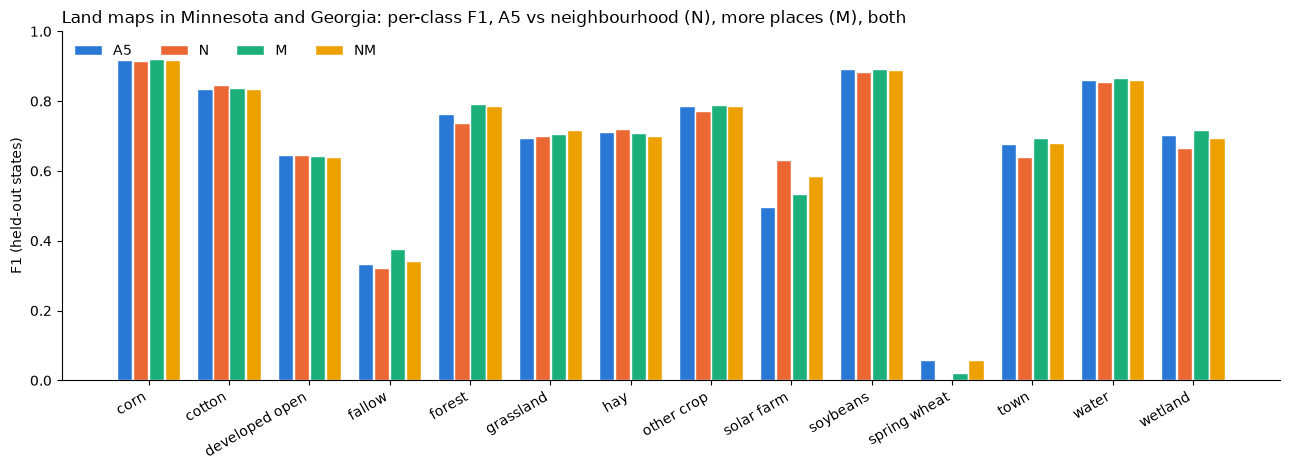

In [12]:
COL = {"A5": "#2a78d6", "N": "#eb6834", "M": "#1baf7a", "NM": "#eda100"}
piv = PER_CLASS.pivot_table(index="leaf", columns="method", values="f1")[METHODS]
fig, ax = plt.subplots(figsize=(13, 4.8))
x = np.arange(len(piv))
for j, m in enumerate(METHODS):
    ax.bar(x + (j - 1.5) * 0.2, piv[m], width=0.19, color=COL[m], label=m, edgecolor="white")
ax.set_xticks(x, [s.replace("_", " ") for s in piv.index], rotation=30, ha="right")
ax.set_ylabel("F1 (held-out states)")
ax.set_ylim(0, 1)
ax.legend(frameon=False, ncol=4, loc="upper left")
ax.set_title(
    "Land maps in Minnesota and Georgia: per-class F1, A5 vs neighbourhood (N), more places (M), both",
    loc="left",
)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
fig.tight_layout()
fig.savefig(FIG / "23_per_class_f1.png", dpi=150)